# 1. Scraping Data Ulasan Bank Jago dari Google Play Store
**Kriteria 1:** Data hasil scraping mandiri menggunakan Python
- App: Bank Jago (com.jago.digitalBanking)
- Target: 10.000+ ulasan unik
- Bahasa: Indonesia

In [1]:
# Cell 1: Imports
from google_play_scraper import reviews, Sort
import pandas as pd
import time

APP_ID = 'com.jago.digitalBanking'
LANG = 'id'
COUNTRY = 'id'

In [2]:
# Cell 2: Scraping function with retry
def scrape_batch(app_id, sort, count, lang='id', country='id'):
    """Scrape a batch of reviews with error handling."""
    try:
        result, _ = reviews(
            app_id,
            lang=lang,
            country=country,
            sort=sort,
            count=count
        )
        return result
    except Exception as e:
        print(f"Error scraping: {e}")
        return []

In [3]:
# Cell 3: Scrape 3 batches
print("Batch 1: Sort.NEWEST (4000 reviews)...")
batch1 = scrape_batch(APP_ID, Sort.NEWEST, 4000)
print(f"  Got {len(batch1)} reviews")
time.sleep(2)

print("Batch 2: Sort.MOST_RELEVANT (4000 reviews)...")
batch2 = scrape_batch(APP_ID, Sort.MOST_RELEVANT, 4000)
print(f"  Got {len(batch2)} reviews")
time.sleep(2)

print("Batch 3: Sort.RATING (4000 reviews)...")
batch3 = scrape_batch(APP_ID, Sort.RATING, 4000)
print(f"  Got {len(batch3)} reviews")

all_reviews = batch1 + batch2 + batch3
print(f"\nTotal raw reviews: {len(all_reviews)}")

Batch 1: Sort.NEWEST (4000 reviews)...
  Got 4000 reviews
Batch 2: Sort.MOST_RELEVANT (4000 reviews)...
  Got 4000 reviews
Batch 3: Sort.RATING (4000 reviews)...
  Got 4000 reviews

Total raw reviews: 12000


In [4]:
# Cell 4: Deduplicate and save
import os
os.makedirs('data', exist_ok=True)
os.makedirs('models', exist_ok=True)

df = pd.DataFrame(all_reviews)

# Keep only needed columns
df = df[['reviewId', 'content', 'score', 'at', 'thumbsUpCount']].copy()

# Drop duplicates by reviewId
before = len(df)
df = df.drop_duplicates(subset='reviewId').reset_index(drop=True)
after = len(df)
print(f"Removed {before - after} duplicates")
print(f"Final dataset size: {after} reviews")

# Drop rows with empty content
df = df.dropna(subset=['content'])
df = df[df['content'].str.strip() != ''].reset_index(drop=True)
print(f"After removing empty content: {len(df)} reviews")

df.to_csv('data/raw_reviews.csv', index=False)
print("Saved to data/raw_reviews.csv")

Removed 2923 duplicates
Final dataset size: 9077 reviews
After removing empty content: 9077 reviews
Saved to data/raw_reviews.csv


score
1    2301
2     316
3     320
4     316
5    5824
Name: count, dtype: int64


C:\Users\ADVAN\AppData\Local\Temp\ipykernel_13604\462293568.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='score', palette='viridis')


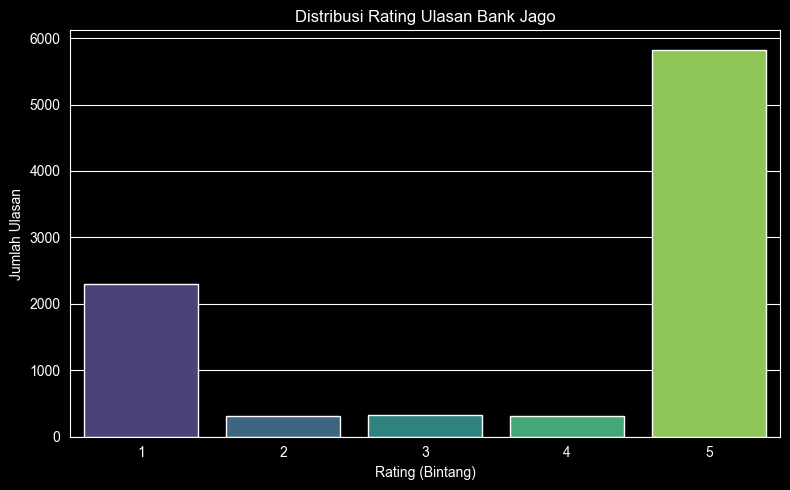


Total data: 9077 ulasan


In [5]:
# Cell 5: Distribution check
import matplotlib.pyplot as plt
import seaborn as sns

print(df['score'].value_counts().sort_index())

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='score', palette='viridis')
plt.title('Distribusi Rating Ulasan Bank Jago')
plt.xlabel('Rating (Bintang)')
plt.ylabel('Jumlah Ulasan')
plt.tight_layout()
plt.savefig('data/rating_distribution.png', dpi=150)
plt.show()
print(f"\nTotal data: {len(df)} ulasan")